# 未实现盈利量（CGO）

**行为金融因子 —— 投资者参考点与盈亏状态**

当前未实现盈利量定义为当前价格相对于参考价格的相对偏离程度：

$$
\text{CGO}_t = \frac{P_t - RP_t}{RP_t}
$$

其中，参考价格 $RP_t$ 采用换手率加权的历史价格进行构造：

$$
RP_t = \frac{1}{k} \sum_{n=1}^{N} V_{t-n} \prod_{\tau=1}^{n-1} \left( 1 - V_{t-\tau} \right) P_{t-n}
$$

各变量定义如下：

* $P_t$ 为股票在 $t$ 时刻的价格；
* $P_{t-n}$ 为股票在 $t-n$ 时刻的价格；
* $V_t$ 为股票在 $t$ 时刻的换手率；
* $V_{t-n}$ 为股票在 $t-n$ 时刻的换手率；
* $\frac{1}{k}$ 为权重归一化参数，确保所有权重之和为 1；
* $N$ 为截断时间长度，通常可取 $N = 40$ 或 $60$ 个交易日。

## 因子说明

未实现盈利量（Capital Gain Overhang，CGO）衡量了当前投资者整体的盈亏水平，其核心逻辑在于通过比较当前价格与参考价格（即投资者的平均持仓成本）来判断市场参与者的盈利或亏损状态。

该因子通常与股票未来收益呈正相关关系：

* 当投资者处于**盈利状态**（$\text{CGO} > 0$）时，由于厌恶风险，他们更倾向于卖出股票以锁定利润，从而形成卖盘压力，导致股价被低估，未来预期收益上升；
* 当投资者处于**亏损状态**（$\text{CGO} < 0$）时，由于偏好风险（即“赌徒心态”或“处置效应”），他们更倾向于继续持有股票而非止损卖出，导致股价被高估，未来预期收益下降。

长期来看，上述现象在 A 股市场是成立的。但在短期内，浮盈股票面临的卖盘压力可能大于其被低估的幅度，从而出现浮盈股票未来表现反而更差的情况。

数据：日度收盘价、日度换手率

In [1]:
from rqdatac import get_turnover_rate
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel


def _get_batch_turnover(batch, dates):
    """
    下载日换手率，返回：日期 × 股票 的宽表。
    字段 today 的单位通常是百分数，例如 0.519 表示 0.519%。
    """
    raw = get_turnover_rate(
        order_book_ids=batch,
        start_date=dates[0],
        end_date=dates[-1],
        fields="today",
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None

    if isinstance(raw.index, pd.MultiIndex):
        turnover = raw["today"].unstack("order_book_id")
    else:
        turnover = raw[["today"]].rename(columns={"today": batch[0]})

    turnover.index = pd.to_datetime(turnover.index)

    return turnover.reindex(index=dates, columns=batch)

def calculate_cgo_daily(
    start_date,
    end_date,
    lookback_window=60,
    candidate_ids=None,
    turnover_is_percent=True,
    batch_size=500,
):
    """
    计算日频未实现盈利量（CGO）。

    RP_t = sum_n[w_t,n * P_t-n] / sum_n[w_t,n]

    w_t,n = V_t-n * product(1 - V_t-tau)
    其中 V 为换手率，后续换手越高，较早成交价格的权重越低。

    CGO_t = (P_t - RP_t) / RP_t

    返回
    ----
    DataFrame
        MultiIndex：date、order_book_id
        Column：CGO
    """
    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=lookback_window,
    )

    candidate_ids = _get_ids(candidate_ids)
    factor_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        # 前复权收盘价用于保证跨除权日的价格可比。
        close, volume = _get_batch_close_volume(batch, price_dates)
        turnover = _get_batch_turnover(batch, price_dates)

        if close is None or turnover is None:
            continue

        # CGO 公式中的 V 必须是 0～1 的比例。
        if turnover_is_percent:
            turnover = turnover / 100.0

        turnover = turnover.clip(lower=0.0, upper=1.0)

        # 停牌／缺失换手率视为未发生筹码交换。
        turnover = turnover.fillna(0.0)

        weight_sum = pd.DataFrame(
            0.0,
            index=price_dates,
            columns=batch,
        )

        weighted_price_sum = pd.DataFrame(
            0.0,
            index=price_dates,
            columns=batch,
        )

        # survival 表示：从历史成交日至今，筹码仍未换手的概率。
        survival = pd.DataFrame(
            1.0,
            index=price_dates,
            columns=batch,
        )

        for lag in range(1, lookback_window + 1):
            turnover_lag = turnover.shift(lag)
            price_lag = close.shift(lag)

            # w_t,n = V_t-n × Π(1 - V_t-tau)
            weight = turnover_lag * survival

            # 价格缺失时不将该观察计入参考价格。
            weight = weight.where(price_lag.notna(), 0.0)

            weighted_price_sum += weight * price_lag.fillna(0.0)
            weight_sum += weight

            # 为下一期更早的历史价格更新留存概率。
            survival *= (1.0 - turnover_lag)

        reference_price = (
            weighted_price_sum
            / weight_sum.replace(0.0, np.nan)
        )

        cgo = (
            (close - reference_price)
            / reference_price
        )

        # CGO 输出要求：
        # 1）当前日有实际成交；
        # 2）此前拥有完整 lookback_window 日价格历史。
        # 3) 防止极少数零价格记录进入窗口
        current_active = volume.gt(0) & close.gt(0)

        history_complete = (
            close.gt(0)
            .rolling(
                window=lookback_window,
                min_periods=lookback_window,
            )
            .sum()
            .shift(1)
            .eq(lookback_window)
        )

        cgo = cgo.where(current_active & history_complete)
        cgo = cgo.reindex(target_dates)

        factor_parts.append(_stack_factor(cgo, "CGO"))

    if not factor_parts:
        return pd.DataFrame(columns=["CGO"])

    return pd.concat(factor_parts).sort_index()

In [2]:
cgo_panel = calculate_cgo_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    lookback_window=60,   # 可改为 40
    turnover_is_percent=True,
)

cgo_panel.head()

CGO
date       order_book_id          
2020-01-02 000001.XSHE    0.031619
           000002.XSHE    0.145481
           000004.XSHE    0.085113
           000005.XSHE    0.006727
           000006.XSHE    0.033074

,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
实际有效观测数,6.744217e+06,
覆盖股票数,5.361000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0
CGO <= -1 的观测数,0.000000e+00,应为 0：价格与参考价均为正时 CGO 必大于 -1



最近 5 个交易日横截面统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,年份,相对覆盖率
date,,,,,,,,,,,,
2025-12-25,5139,-0.008357,0.073987,-0.491983,-0.021068,1.441454,-0.130812,-0.096255,0.112525,0.220101,2025,0.999028
2025-12-26,5140,-0.009278,0.077138,-0.462552,-0.023745,1.621888,-0.131094,-0.096585,0.121740,0.230148,2025,0.999222
2025-12-29,5143,-0.011915,0.077621,-0.501098,-0.026143,1.590230,-0.137792,-0.100098,0.113727,0.233805,2025,0.999806
2025-12-30,5142,-0.015307,0.076519,-0.565682,-0.029430,1.787731,-0.142189,-0.104305,0.111959,0.222832,2025,0.999611
2025-12-31,5144,-0.014664,0.077267,-0.418867,-0.028405,1.910662,-0.145038,-0.103170,0.117299,0.219604,2025,1.000000



CGO 最大的 20 条记录：


,date,order_book_id,CGO
5249110,2024-10-23,300489.XSHE,3.166487
6179503,2025-07-22,688585.XSHG,3.003853
6174386,2025-07-21,688585.XSHG,3.001779
6169267,2025-07-18,688585.XSHG,2.959725
5244034,2024-10-22,300489.XSHE,2.643468
3197205,2023-02-13,302132.XSHE,2.581526
3196099,2023-02-13,300114.XSHE,2.581526
6399473,2025-09-19,605255.XSHG,2.531906
6404606,2025-09-22,605255.XSHG,2.498237
6409742,2025-09-23,605255.XSHG,2.461076



CGO 最小的 20 条记录：


,date,order_book_id,CGO
4783701,2024-06-05,600766.XSHG,-0.977177
4788786,2024-06-06,600766.XSHG,-0.946920
4757937,2024-05-29,600306.XSHG,-0.929920
4784213,2024-06-05,603133.XSHG,-0.927169
3549089,2023-05-30,600532.XSHG,-0.919328
3554179,2023-05-31,600767.XSHG,-0.918770
6077436,2025-06-25,000622.XSHE,-0.918651
4763017,2024-05-30,600306.XSHG,-0.917995
2399124,2022-06-02,600870.XSHG,-0.917897
4793869,2024-06-07,600766.XSHG,-0.917871


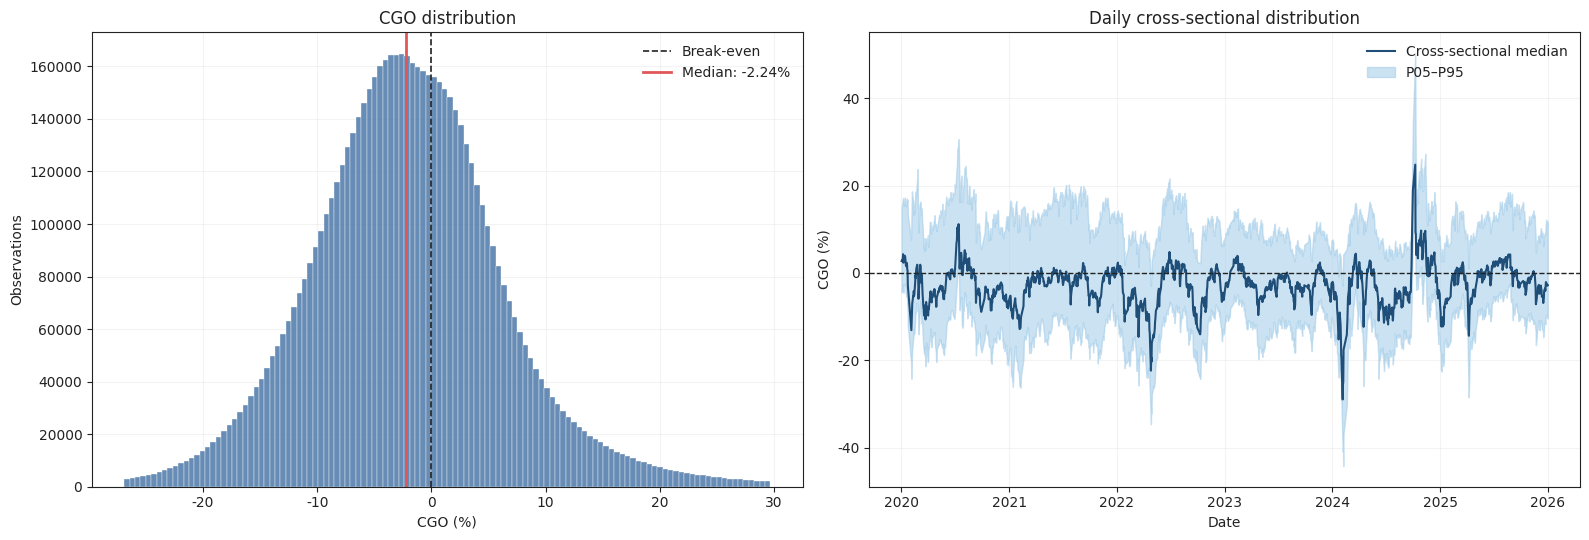

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from rqdatac import all_instruments, get_trading_dates

FACTOR_NAME = "CGO"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"
LOOKBACK_WINDOW = 60

panel = cgo_panel.copy()

if not isinstance(panel.index, pd.MultiIndex):
    raise ValueError("cgo_panel 应为 date、order_book_id 两层 MultiIndex。")

if FACTOR_NAME not in panel.columns:
    raise ValueError("未找到因子列：{}".format(FACTOR_NAME))

check_data = pd.DataFrame({
    "date": pd.to_datetime(panel.index.get_level_values("date")),
    "order_book_id": panel.index.get_level_values("order_book_id"),
    FACTOR_NAME: pd.to_numeric(panel[FACTOR_NAME], errors="coerce").values,
})

expected_dates = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=START_DATE,
            end_date=END_DATE,
        )
    )
)

raw_value = check_data[FACTOR_NAME]
is_finite = pd.Series(
    np.isfinite(raw_value.values),
    index=check_data.index,
)

valid = check_data.loc[is_finite].copy()

# ---------- 每日横截面覆盖与统计 ----------
daily = valid.groupby("date")[FACTOR_NAME].agg(
    ["count", "mean", "std", "min", "median", "max"]
)
daily.columns = ["因子股票数", "均值", "标准差", "最小值", "中位数", "最大值"]

daily["P01"] = valid.groupby("date")[FACTOR_NAME].quantile(0.01)
daily["P05"] = valid.groupby("date")[FACTOR_NAME].quantile(0.05)
daily["P95"] = valid.groupby("date")[FACTOR_NAME].quantile(0.95)
daily["P99"] = valid.groupby("date")[FACTOR_NAME].quantile(0.99)

daily = daily.reindex(expected_dates)
daily.index.name = "date"
daily["因子股票数"] = daily["因子股票数"].fillna(0)

daily["年份"] = daily.index.year
year_max_count = daily.groupby("年份")["因子股票数"].transform("max")
daily["相对覆盖率"] = (
    daily["因子股票数"]
    / year_max_count.replace(0, np.nan)
)

stock_days = valid.groupby("order_book_id").size()

# ---------- 检查首次因子值是否早于 60 日历史要求 ----------
first_factor_date = valid.groupby("order_book_id")["date"].min()

instruments_df = (
    all_instruments("CS")
    .drop_duplicates("order_book_id")
    .set_index("order_book_id")
)

listed_dates = pd.to_datetime(
    instruments_df["listed_date"].reindex(first_factor_date.index),
    errors="coerce",
)

calendar = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=END_DATE,
        )
    )
)

listing_locs = calendar.searchsorted(listed_dates.values, side="left")
factor_locs = calendar.searchsorted(first_factor_date.values, side="left")

history_age = pd.Series(
    factor_locs - listing_locs,
    index=first_factor_date.index,
)

early_factor_stocks = history_age[
    history_age < LOOKBACK_WINDOW
].sort_values()

# ---------- 因子日变化 ----------
sorted_valid = valid.sort_values(["order_book_id", "date"])
daily_abs_change = (
    sorted_valid.groupby("order_book_id")[FACTOR_NAME]
    .diff()
    .abs()
    .dropna()
)

summary = pd.DataFrame([
    ["目标交易日数", len(expected_dates), ""],
    ["有至少一个因子值的交易日数", int((daily["因子股票数"] > 0).sum()),
     "应接近目标交易日数"],
    ["完全无输出交易日数", int((daily["因子股票数"] == 0).sum()),
     "应为 0"],
    ["实际有效观测数", len(valid), ""],
    ["覆盖股票数", valid["order_book_id"].nunique(), ""],
    ["重复 date-stock", int(check_data.duplicated(["date", "order_book_id"]).sum()),
     "应为 0"],
    ["显式缺失值", int(raw_value.isna().sum()),
     "最终 stack 后通常应为 0"],
    ["无穷值（inf/-inf）", int(np.isinf(raw_value.values).sum()),
     "应为 0"],
    ["CGO <= -1 的观测数", int((raw_value <= -1).sum()),
     "应为 0：价格与参考价均为正时 CGO 必大于 -1"],
    ["零值占比", float((raw_value == 0).mean()),
     "允许为 0，表示当前价等于参考价"],
    ["每日因子股票数均值", daily["因子股票数"].mean(), ""],
    ["每日因子股票数 P05", daily["因子股票数"].quantile(0.05),
     "检查低覆盖交易日"],
    ["相对覆盖率 P05", daily["相对覆盖率"].quantile(0.05),
     "建议大于 0.80"],
    ["单股有效天数 P05", stock_days.quantile(0.05), ""],
    ["上市不足 {} 日即产生因子的股票数".format(LOOKBACK_WINDOW),
     len(early_factor_stocks),
     "应为 0"],
    ["正值占比", float((valid[FACTOR_NAME] > 0).mean()),
     "浮盈股票占比"],
    ["均值", valid[FACTOR_NAME].mean(), ""],
    ["标准差", valid[FACTOR_NAME].std(), ""],
    ["最小值", valid[FACTOR_NAME].min(),
     "理论上应大于 -1"],
    ["P01", valid[FACTOR_NAME].quantile(0.01), ""],
    ["中位数", valid[FACTOR_NAME].median(),
     "典型股票相对参考价的浮盈/浮亏"],
    ["P99", valid[FACTOR_NAME].quantile(0.99), ""],
    ["最大值", valid[FACTOR_NAME].max(),
     "核对新股、复牌、重大事件或参考价过低"],
    ["CGO > 100% 的观测数", int((valid[FACTOR_NAME] > 1).sum()),
     "人工复核阈值"],
    ["CGO < -80% 的观测数", int((valid[FACTOR_NAME] < -0.8).sum()),
     "人工复核阈值"],
    ["日变化绝对值 P99", daily_abs_change.quantile(0.99),
     "过大跳变时核对复牌或参考价异常"],
], columns=["指标", "数值", "判断"])

display(summary.set_index("指标"))

print("\n最近 5 个交易日横截面统计：")
display(daily.tail())

print("\nCGO 最大的 20 条记录：")
display(
    valid.sort_values(FACTOR_NAME, ascending=False)
    .head(20)[["date", "order_book_id", FACTOR_NAME]]
)

print("\nCGO 最小的 20 条记录：")
display(
    valid.sort_values(FACTOR_NAME, ascending=True)
    .head(20)[["date", "order_book_id", FACTOR_NAME]]
)

if len(early_factor_stocks) > 0:
    print("\n上市历史不足 {} 日就产生 CGO 的股票：".format(LOOKBACK_WINDOW))
    display(early_factor_stocks.head(20).to_frame("上市至首次因子值的交易日数"))

# ---------- 白底分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
    "axes.unicode_minus": False,
})

cgo_pct = valid[FACTOR_NAME] * 100
lower = cgo_pct.quantile(0.005)
upper = cgo_pct.quantile(0.995)
hist_values = cgo_pct[
    (cgo_pct >= lower)
    & (cgo_pct <= upper)
]

plot_daily = daily.dropna(subset=["P05", "中位数", "P95"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].hist(
    hist_values,
    bins=120,
    color="#4C78A8",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[0].axvline(
    0,
    color="#222222",
    linewidth=1.2,
    linestyle="--",
    label="Break-even",
)
axes[0].axvline(
    cgo_pct.median(),
    color="#E15759",
    linewidth=2,
    label="Median: {:.2f}%".format(cgo_pct.median()),
)
axes[0].set_title("CGO distribution")
axes[0].set_xlabel("CGO (%)")
axes[0].set_ylabel("Observations")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

axes[1].fill_between(
    plot_daily.index,
    (plot_daily["P05"] * 100).values,
    (plot_daily["P95"] * 100).values,
    color="#A0CBE8",
    alpha=0.55,
    label="P05–P95",
)
axes[1].plot(
    plot_daily.index,
    (plot_daily["中位数"] * 100).values,
    color="#1F4E79",
    linewidth=1.5,
    label="Cross-sectional median",
)
axes[1].axhline(
    0,
    color="#222222",
    linewidth=1,
    linestyle="--",
)
axes[1].set_title("Daily cross-sectional distribution")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("CGO (%)")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

这次 CGO 输出通过完整性与主体数值合理性检验。

- 全部 1,455 个交易日均有输出；无重复、缺失、无穷值；
- 没有 `CGO <= -1`，符合 \(P_t>0\)、\(RP_t>0\) 时的理论下界；
- 上市不足 60 个交易日的输出为 0；
- 覆盖率 P05 为 91.7%，稳定；
- 全样本中位数 `-2.24%`、均值 `-2.00%`、P01 `-23.20%`、P99 `24.20%`，对 60 日参考价格的 CGO 而言合理；
- 正值占比 `38.76%`，说明样本期内更多股票价格低于其换手加权持仓成本；这属于市场状态结果，不是计算错误；
- 2025 年末截面中位数约 `-2%` 至 `-3%`、P01 约 `-13%`、P99 约 `22%`，分布稳定。

极端值需要定性复核，但目前不构成数据失败：

- 最大 `3.1665`：当前价格约为参考价的 `4.17` 倍；
- 最小 `-0.9772`：当前价格约为参考价的 `2.28%`；
- `CGO > 100%` 仅 230 条、`CGO < -80%` 仅 144 条，占全部 674 万条观测的比例极低；
- 同一股票连续多日位于极端区域是合理的，CGO 是持仓成本参考价模型，不会像日收益率一样次日归零。

建议对最大与最小各复核一只，确认参考价没有被极低换手率扭曲：

```python
inspect_cgo_extreme("300489.XSHE", "2024-10-23")
inspect_cgo_extreme("600766.XSHG", "2024-06-05")
```

若尚未定义该函数，可以先不处理；从当前统计看，CGO 已可进入后续回测。实际使用时建议按日做 0.5%–99.5% 缩尾，再进行横截面标准化。

In [4]:
def inspect_cgo_extreme(
    stock_id,
    factor_date,
    lookback_window=60,
    turnover_is_percent=True,
):
    """
    复现指定股票、指定日期的 CGO，并展示参考价的历史权重构成。

    返回
    ----
    summary : DataFrame
        当前价格、参考价格、CGO、权重和等摘要。

    details : DataFrame
        过去 lookback_window 日的换手率、价格、留存概率与权重明细。
    """
    factor_date = pd.Timestamp(factor_date)

    # 预留足够自然日，随后精确截取最后 lookback_window + 1 个交易日。
    calendar = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(
                start_date=factor_date - pd.Timedelta(
                    days=max(lookback_window * 3, 120)
                ),
                end_date=factor_date,
            )
        )
    )

    if factor_date not in calendar:
        raise ValueError("{} 不是交易日。".format(factor_date.date()))

    if len(calendar) < lookback_window + 1:
        raise ValueError("历史交易日不足，无法复现 CGO。")

    dates = calendar[-(lookback_window + 1):]

    close, volume = _get_batch_close_volume([stock_id], dates)
    turnover = _get_batch_turnover([stock_id], dates)

    if close is None or turnover is None:
        raise ValueError("无法获取 {} 的价格或换手率数据。".format(stock_id))

    close_s = close[stock_id]
    volume_s = volume[stock_id]
    turnover_s = turnover[stock_id].copy()

    if turnover_is_percent:
        turnover_s = turnover_s / 100.0

    turnover_s = turnover_s.clip(lower=0.0, upper=1.0).fillna(0.0)

    current_price = close_s.iloc[-1]
    current_volume = volume_s.iloc[-1]
    current_turnover = turnover_s.iloc[-1]

    current_active = (
        pd.notna(current_price)
        and current_price > 0
        and pd.notna(current_volume)
        and current_volume > 0
    )

    history_complete = close_s.iloc[:-1].notna().all()

    survival = 1.0
    rows = []

    for lag in range(1, lookback_window + 1):
        pos = -1 - lag

        historical_date = dates[pos]
        historical_price = close_s.iloc[pos]
        historical_turnover = turnover_s.iloc[pos]

        raw_weight = historical_turnover * survival

        # 与原 CGO 函数完全一致：历史价格缺失时不计入参考价。
        if pd.notna(historical_price):
            used_weight = raw_weight
        else:
            used_weight = 0.0

        rows.append([
            lag,
            historical_date,
            historical_price,
            volume_s.iloc[pos],
            historical_turnover,
            survival,
            raw_weight,
            used_weight,
        ])

        # 更新更早期筹码的留存概率。
        survival *= (1.0 - historical_turnover)

    details = pd.DataFrame(
        rows,
        columns=[
            "lag",
            "historical_date",
            "historical_close",
            "historical_volume",
            "turnover_rate",
            "survival_before",
            "raw_weight",
            "used_weight",
        ],
    )

    weight_sum = details["used_weight"].sum()

    if weight_sum <= 0:
        reference_price = np.nan
        reproduced_cgo = np.nan
    else:
        reference_price = (
            details["used_weight"] * details["historical_close"]
        ).sum() / weight_sum

        reproduced_cgo = current_price / reference_price - 1.0

    details["normalized_weight"] = (
        details["used_weight"] / weight_sum
        if weight_sum > 0 else np.nan
    )

    details["price_contribution"] = (
        details["normalized_weight"]
        * details["historical_close"]
    )

    summary = pd.DataFrame([
        ["股票", stock_id],
        ["因子日期", factor_date],
        ["当前收盘价", current_price],
        ["当前成交量", current_volume],
        ["当前换手率", current_turnover],
        ["当前日是否成交", current_active],
        ["此前 {} 日价格是否完整".format(lookback_window), history_complete],
        ["参考价格 RP", reference_price],
        ["权重和", weight_sum],
        ["窗口后剩余未换手概率", survival],
        ["复现 CGO", reproduced_cgo],
    ], columns=["项目", "数值"])

    display(summary)

    print("\n参考价格权重最大的 15 个历史交易日：")
    display(
        details.sort_values(
            "normalized_weight",
            ascending=False,
        ).head(15)
    )

    print("\n过去 {} 个交易日的完整权重明细：".format(lookback_window))
    display(details.sort_values("historical_date"))

    return summary, details

inspect_cgo_extreme("300489.XSHE", "2024-10-23")

,项目,数值
0,股票,300489.XSHE
1,因子日期,2024-10-23 00:00:00
2,当前收盘价,97.97
3,当前成交量,37750993.0
4,当前换手率,0.275225
5,当前日是否成交,True
6,此前 60 日价格是否完整,True
7,参考价格 RP,23.513816
8,权重和,0.541036
9,窗口后剩余未换手概率,0.458964



参考价格权重最大的 15 个历史交易日：


,lag,historical_date,historical_close,historical_volume,turnover_rate,survival_before,raw_weight,used_weight,normalized_weight,price_contribution
18,19,2024-09-19,20.22,6148365.0,0.044825,0.818308,0.036681,0.036681,0.067797,1.370857
19,20,2024-09-18,19.25,6141401.0,0.044774,0.781627,0.034997,0.034997,0.064684,1.245175
12,13,2024-09-27,22.78,4686340.0,0.034166,0.940628,0.032137,0.032137,0.059400,1.353130
14,15,2024-09-25,20.80,3381160.0,0.024651,0.893539,0.022027,0.022027,0.040712,0.846809
16,17,2024-09-23,20.30,3093450.0,0.022553,0.853813,0.019256,0.019256,0.035591,0.722498
15,16,2024-09-24,20.77,2785700.0,0.020309,0.871513,0.017700,0.017700,0.032714,0.679473
2,3,2024-10-18,56.69,2306992.0,0.016819,0.980843,0.016497,0.016497,0.030491,1.728541
17,18,2024-09-20,19.94,2670515.0,0.019470,0.834557,0.016249,0.016249,0.030033,0.598854
28,29,2024-09-03,17.62,3141600.0,0.022904,0.690631,0.015818,0.015818,0.029237,0.515154
13,14,2024-09-26,21.28,2257350.0,0.016457,0.908490,0.014951,0.014951,0.027634,0.588053



过去 60 个交易日的完整权重明细：


,lag,historical_date,historical_close,historical_volume,turnover_rate,survival_before,raw_weight,used_weight,normalized_weight,price_contribution
59,60,2024-07-22,20.75,2138200.0,0.015589,0.466232,0.007268,0.007268,0.013434,0.278748
58,59,2024-07-23,20.05,2977200.0,0.021705,0.476576,0.010344,0.010344,0.019119,0.383337
57,58,2024-07-24,19.44,2560600.0,0.018668,0.485642,0.009066,0.009066,0.016757,0.325750
56,57,2024-07-25,19.40,1290300.0,0.009407,0.490254,0.004612,0.004612,0.008524,0.165367
55,56,2024-07-26,19.76,1465000.0,0.010681,0.495547,0.005293,0.005293,0.009783,0.193311
54,55,2024-07-29,20.08,1832600.0,0.013361,0.502258,0.006711,0.006711,0.012403,0.249059
53,54,2024-07-30,19.21,2177527.0,0.015875,0.510359,0.008102,0.008102,0.014975,0.287668
52,53,2024-07-31,19.62,2022950.0,0.014748,0.517999,0.007639,0.007639,0.014120,0.277035
51,52,2024-08-01,19.55,1778900.0,0.012969,0.524805,0.006806,0.006806,0.012580,0.245938
50,51,2024-08-02,19.00,1865485.0,0.013600,0.532041,0.007236,0.007236,0.013374,0.254104


(               项目                   数值
 0              股票          300489.XSHE
 1            因子日期  2024-10-23 00:00:00
 2           当前收盘价                97.97
 3           当前成交量           37750993.0
 4           当前换手率             0.275225
 5         当前日是否成交                 True
 6   此前 60 日价格是否完整                 True
 7         参考价格 RP            23.513816
 8             权重和             0.541036
 9      窗口后剩余未换手概率             0.458964
 10         复现 CGO             3.166487,
     lag historical_date  historical_close  historical_volume  turnover_rate  \
 0     1      2024-10-22             81.64          1346779.0       0.009819   
 1     2      2024-10-21             68.03          1293660.0       0.009431   
 2     3      2024-10-18             56.69          2306992.0       0.016819   
 3     4      2024-10-17             47.24          1238200.0       0.009027   
 4     5      2024-10-16             39.37          1131300.0       0.008248   
 5     6      2024-10-15             32

In [5]:
inspect_cgo_extreme("600766.XSHG", "2024-06-05")

,项目,数值
0,股票,600766.XSHG
1,因子日期,2024-06-05 00:00:00
2,当前收盘价,0.35
3,当前成交量,43414506.0
4,当前换手率,0.193874
5,当前日是否成交,True
6,此前 60 日价格是否完整,True
7,参考价格 RP,15.335071
8,权重和,0.205676
9,窗口后剩余未换手概率,0.794324



参考价格权重最大的 15 个历史交易日：


,lag,historical_date,historical_close,historical_volume,turnover_rate,survival_before,raw_weight,used_weight,normalized_weight,price_contribution
39,40,2024-04-03,15.94,3705017.0,0.016545,0.931931,0.015419,0.015419,0.074966,1.194965
38,39,2024-04-08,15.50,3537355.0,0.015797,0.946889,0.014958,0.014958,0.072726,1.127254
40,41,2024-04-02,16.77,3378085.0,0.015085,0.916512,0.013826,0.013826,0.067220,1.127283
31,32,2024-04-17,13.99,2578516.0,0.011515,0.985075,0.011343,0.011343,0.055150,0.771555
47,48,2024-03-22,15.57,2636055.0,0.011772,0.872647,0.010273,0.010273,0.049947,0.777667
46,47,2024-03-25,15.19,2574885.0,0.011499,0.882798,0.010151,0.010151,0.049356,0.749714
57,58,2024-03-08,16.14,2484317.0,0.011094,0.815916,0.009052,0.009052,0.044010,0.710319
51,52,2024-03-18,15.20,2011000.0,0.008980,0.841524,0.007557,0.007557,0.036742,0.558473
48,49,2024-03-21,14.83,1943800.0,0.008680,0.862374,0.007485,0.007485,0.036394,0.539725
58,59,2024-03-07,16.49,2049306.0,0.009151,0.806864,0.007384,0.007384,0.035899,0.591978



过去 60 个交易日的完整权重明细：


,lag,historical_date,historical_close,historical_volume,turnover_rate,survival_before,raw_weight,used_weight,normalized_weight,price_contribution
59,60,2024-03-06,15.70,1444400.0,0.006450,0.799481,0.005157,0.005157,0.025072,0.393626
58,59,2024-03-07,16.49,2049306.0,0.009151,0.806864,0.007384,0.007384,0.035899,0.591978
57,58,2024-03-08,16.14,2484317.0,0.011094,0.815916,0.009052,0.009052,0.044010,0.710319
56,57,2024-03-11,16.10,1424237.0,0.006360,0.821138,0.005222,0.005222,0.025392,0.408804
55,56,2024-03-12,15.80,1075700.0,0.004804,0.825102,0.003964,0.003964,0.019272,0.304498
54,55,2024-03-13,15.90,704000.0,0.003144,0.827705,0.002602,0.002602,0.012652,0.201174
53,54,2024-03-14,15.85,753400.0,0.003364,0.830498,0.002794,0.002794,0.013583,0.215298
52,53,2024-03-15,15.68,931320.0,0.004159,0.833967,0.003468,0.003468,0.016864,0.264423
51,52,2024-03-18,15.20,2011000.0,0.008980,0.841524,0.007557,0.007557,0.036742,0.558473
50,51,2024-03-19,15.32,1882700.0,0.008407,0.848658,0.007135,0.007135,0.034689,0.531433


(               项目                   数值
 0              股票          600766.XSHG
 1            因子日期  2024-06-05 00:00:00
 2           当前收盘价                 0.35
 3           当前成交量           43414506.0
 4           当前换手率             0.193874
 5         当前日是否成交                 True
 6   此前 60 日价格是否完整                 True
 7         参考价格 RP            15.335071
 8             权重和             0.205676
 9      窗口后剩余未换手概率             0.794324
 10         复现 CGO            -0.977177,
     lag historical_date  historical_close  historical_volume  turnover_rate  \
 0     1      2024-06-04              9.84                0.0       0.000000   
 1     2      2024-06-03              9.84                0.0       0.000000   
 2     3      2024-05-31              9.84                0.0       0.000000   
 3     4      2024-05-30              9.84                0.0       0.000000   
 4     5      2024-05-29              9.84                0.0       0.000000   
 5     6      2024-05-28              9

两个极端值都被正确复现，CGO 的加权与归一化计算没有错误。

`300489.XSHE` 的正向极端值是可信的：

- 当前价 `97.97`，参考价 `23.51`，复现 CGO 为 `3.1665`；
- 60 日内累计有效权重为 `0.541`，参考价由多日、较分散的换手权重构成，最大单日权重仅约 `6.8%`；
- 因此这不是“极低换手率导致参考价失真”，而是近期价格从约 20 元快速上涨至近 98 元后的真实浮盈状态。

`600766.XSHG` 的负向极端值也符合当前公式，但属于特殊停牌重估情形：

- 当前价 `0.35`，参考价 `15.34`，复现 CGO 为 `-0.9772`；
- 参考价主要来自 2024 年 3–4 月的正常交易价格；
- 4 月底至 6 月初存在连续零成交日，期间换手率为 0，因此模型自然认为筹码未换手、历史持仓成本仍然留存；
- 复牌/恢复交易后价格大幅重置至 `0.35`，便得到接近 `-100%` 的 CGO。

所以，`600766.XSHG` 不是程序或公式错误，而是 CGO 对“长期停牌后价格剧烈变化”非常敏感的正常结果。

若研究目标是完整刻画投资者浮盈浮亏状态，可以保留这类观测；若目标是可交易股票池中的稳健选股因子，建议加入“过去 60 日至少有 50 日实际成交”的可交易性过滤，排除类似长期停牌后的重估事件。

在 `calculate_cgo_daily` 中增加参数：

```python
min_active_history_days=50,
```

并在 `history_complete` 后加入：

```python
history_active_days = (
    volume.gt(0)
    .rolling(
        window=lookback_window,
        min_periods=lookback_window,
    )
    .sum()
    .shift(1)
)
```

最后将输出条件改为：

```python
cgo = cgo.where(
    current_active
    & history_complete
    & history_active_days.ge(min_active_history_days)
)
```

这个过滤不会影响 `300489.XSHE` 这类仅有少量停牌日、但真实持续上涨的高 CGO；会过滤 `600766.XSHG` 这类历史窗口内存在长期零成交的特殊事件。

In [6]:
# 行：交易日；列：order_book_id；值：ABNRETD
cgo_panel_df = (
    cgo_panel["CGO"]
    .unstack("order_book_id")
    .sort_index()
)

cgo_panel_df.index = pd.to_datetime(cgo_panel_df.index)
cgo_panel_df.columns.name = "order_book_id"

cgo_panel_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688787.XSHG,688788.XSHG,688789.XSHG,688793.XSHG,688798.XSHG,688799.XSHG,688800.XSHG,688819.XSHG,688981.XSHG,689009.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.031619,0.145481,0.085113,0.006727,0.033074,-0.053420,0.035975,0.184202,-0.010335,0.016800,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.049288,0.121229,0.082114,0.010039,0.046882,-0.057441,0.045301,0.105470,-0.009938,0.014738,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.041164,0.098400,0.050193,0.010274,0.040545,-0.060712,0.038017,0.201290,-0.004022,0.004408,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.045853,0.103376,0.064212,0.026668,0.044810,-0.057737,0.053161,0.202423,0.027874,0.022231,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.016601,0.097384,0.045810,0.010558,0.024572,-0.068717,0.032060,0.155961,0.016591,-0.005275,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.004126,-0.126302,-0.066575,NaN,-0.111673,0.102093,-0.062464,-0.076120,-0.051558,-0.097050,...,-0.026234,0.185895,0.007347,-0.071630,-0.028831,-0.033968,0.125471,0.025759,0.012388,-0.014889
2025-12-26,0.001929,-0.126272,-0.068027,NaN,-0.100508,0.081457,-0.062009,-0.071273,-0.068167,-0.098999,...,0.022076,0.084975,0.007423,-0.206469,-0.030641,-0.053753,0.089978,0.038087,0.005429,-0.050167
2025-12-29,0.003301,-0.128230,-0.067996,NaN,-0.133340,0.075451,-0.067835,-0.083702,-0.061252,-0.109553,...,0.013300,0.073430,-0.001177,-0.184614,-0.026818,-0.052006,0.127953,0.020424,0.009603,-0.068256


In [7]:
from rqfactor.notebook import factor_analysis

result_cgo = factor_analysis(
    f=cgo_panel_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_cgo.show()

Loading BokehJS ...

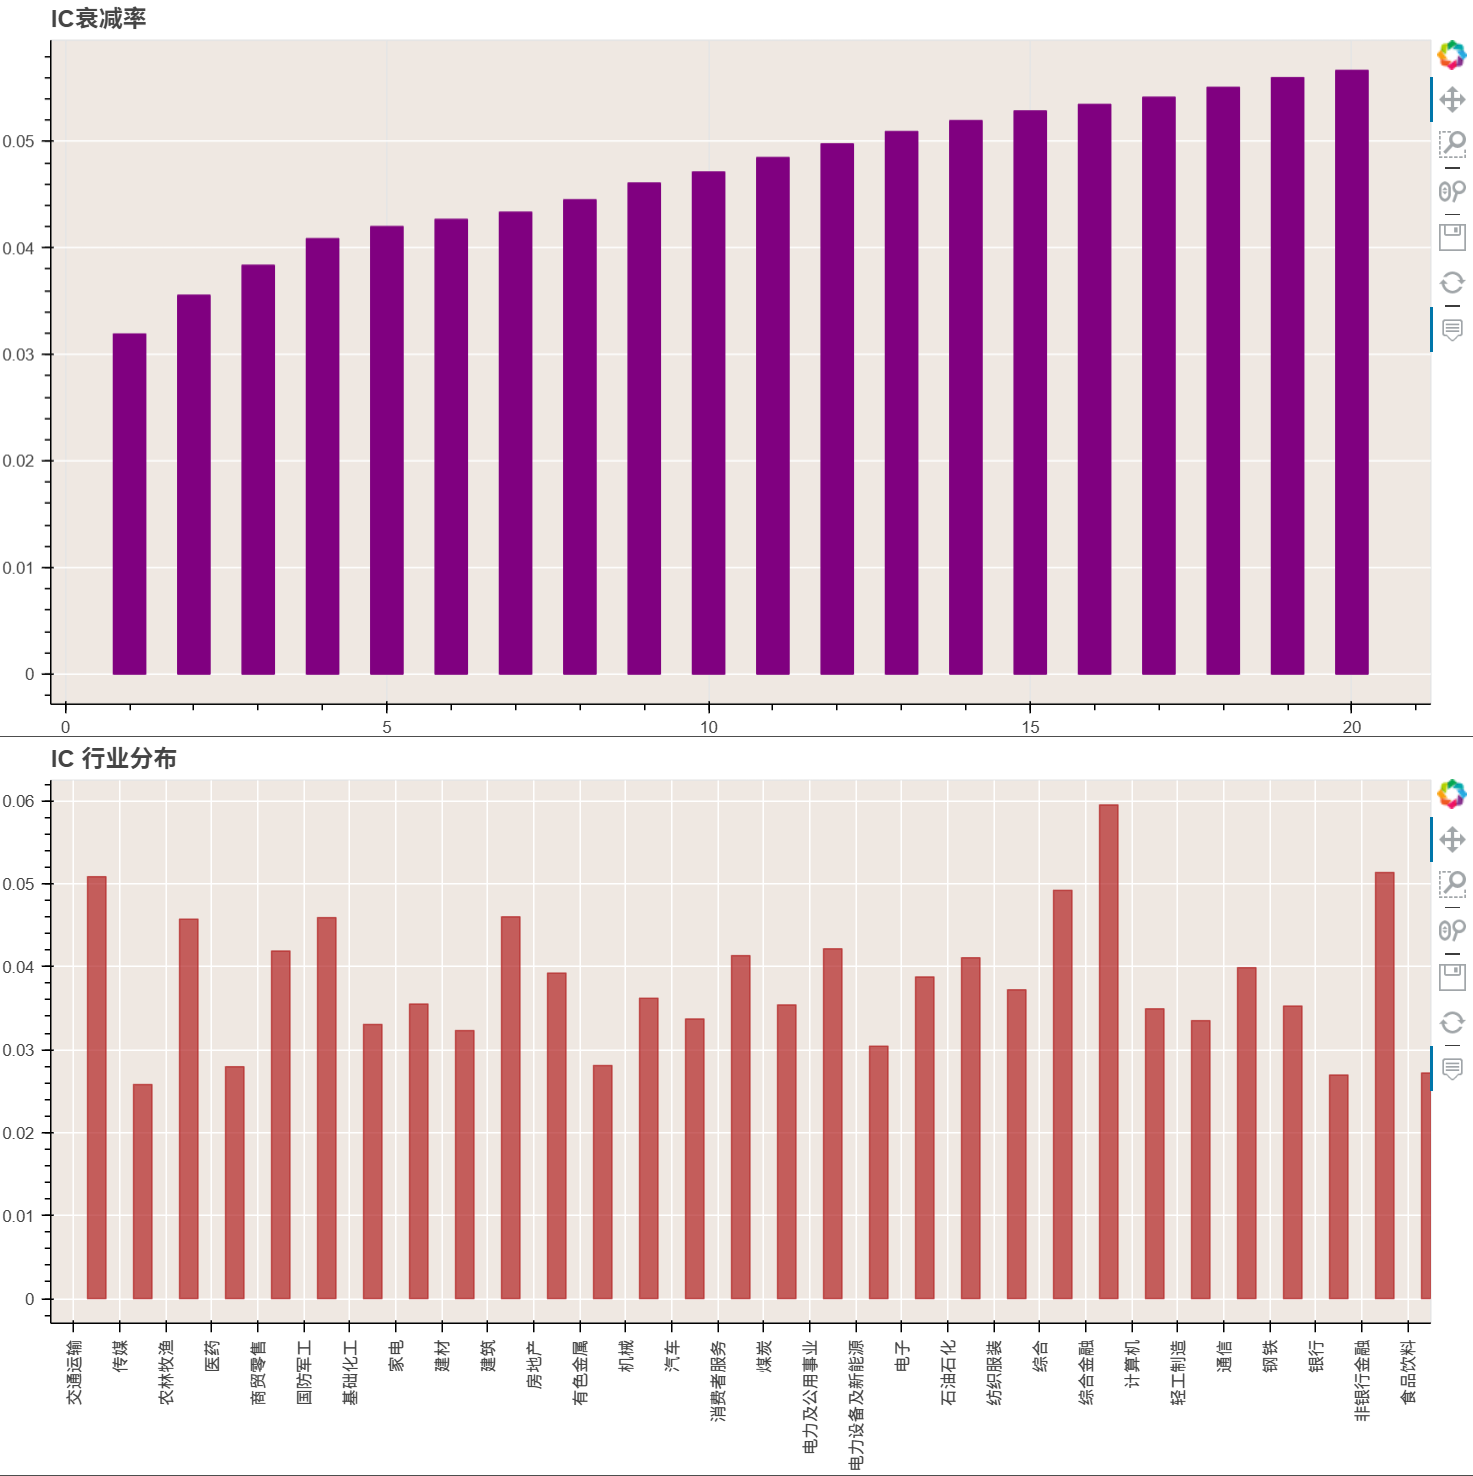

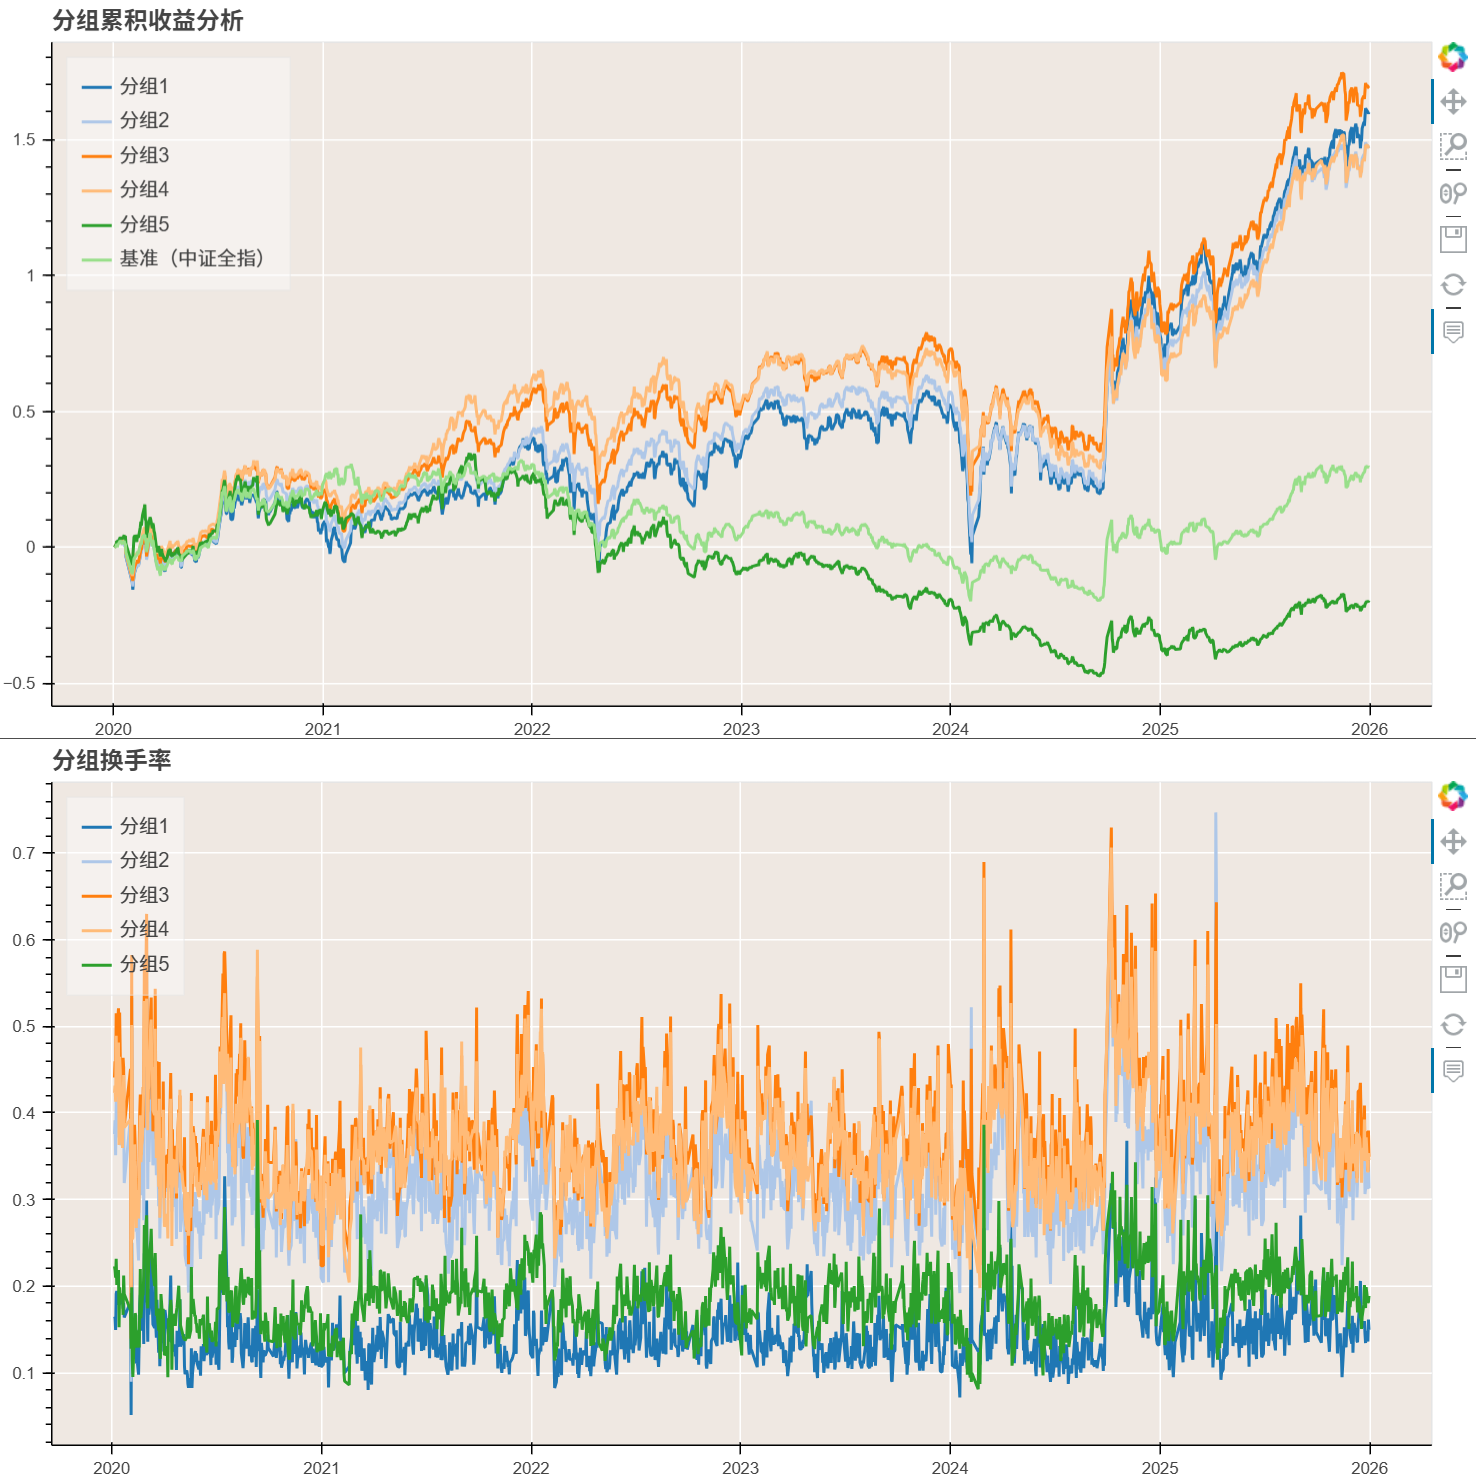

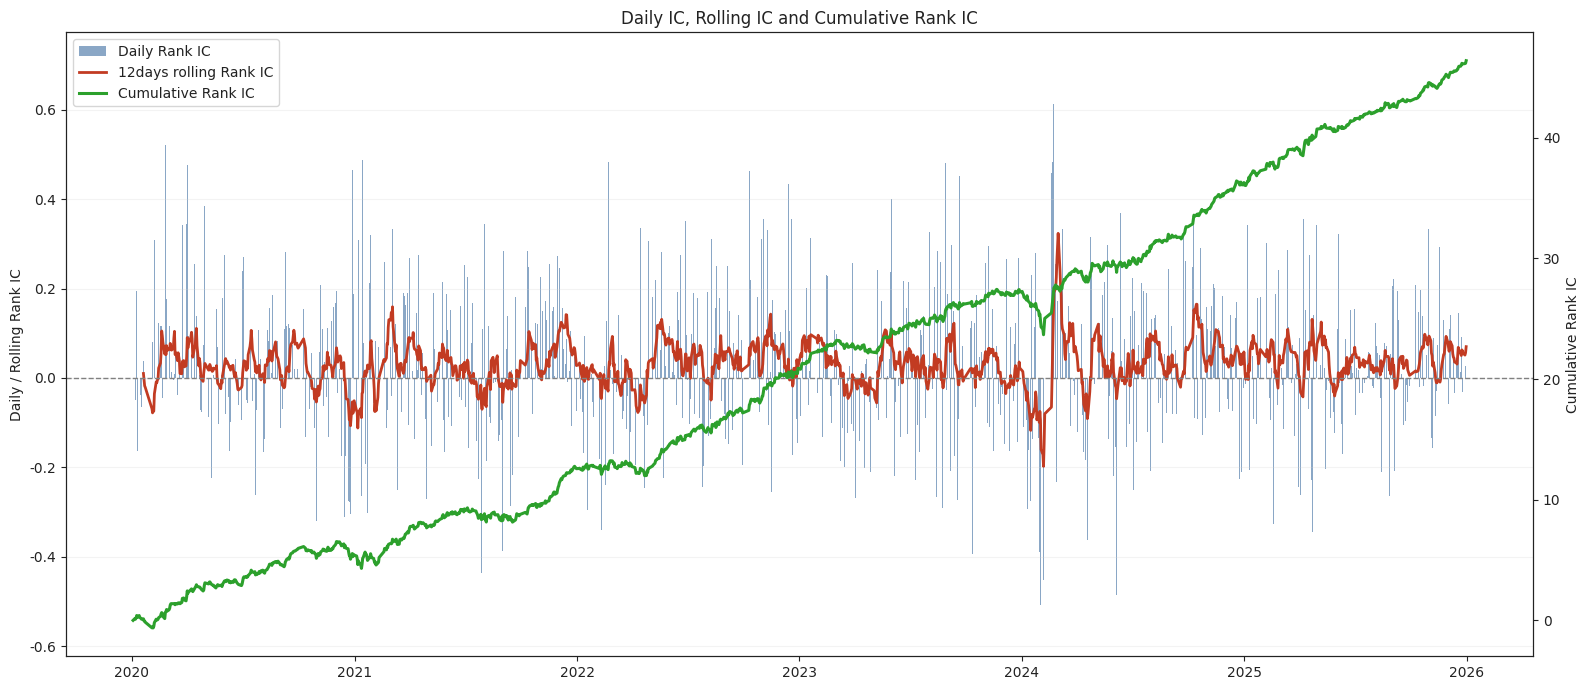

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_cgo.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()